Project root: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction
Tuning records: 12
Mathematics: train=(316, 30), test=(79, 30)
Portuguese: train=(519, 30), test=(130, 30)
Evaluated Mathematics - Logistic Regression | F1=0.6800
Evaluated Mathematics - Decision Tree | F1=0.8000
Evaluated Mathematics - Random Forest | F1=0.7759
Evaluated Mathematics - SVM | F1=0.8103
Evaluated Mathematics - KNN | F1=0.5814
Evaluated Mathematics - ANN | F1=0.7778
Evaluated Portuguese - Logistic Regression | F1=0.7960
Evaluated Portuguese - Decision Tree | F1=0.8505
Evaluated Portuguese - Random Forest | F1=0.8761
Evaluated Portuguese - SVM | F1=0.8919
Evaluated Portuguese - KNN | F1=0.7716
Evaluated Portuguese - ANN | F1=0.8341

FINAL TEST-SET EVALUATION


,Dataset,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
3,Mathematics,SVM,0.7215,0.7460,0.8868,0.8103,0.7199
1,Mathematics,Decision Tree,0.7342,0.8077,0.7925,0.8000,0.5929
5,Mathematics,ANN,0.6962,0.7636,0.7925,0.7778,0.6858
2,Mathematics,Random Forest,0.6709,0.7143,0.8491,0.7759,0.6466
0,Mathematics,Logistic Regression,0.5949,0.7234,0.6415,0.6800,0.6060
4,Mathematics,KNN,0.5443,0.7576,0.4717,0.5814,0.5922
9,Portuguese,SVM,0.8154,0.8839,0.9000,0.8919,0.6655
8,Portuguese,Random Forest,0.7846,0.8534,0.9000,0.8761,0.6841
7,Portuguese,Decision Tree,0.7538,0.8750,0.8273,0.8505,0.5934
11,Portuguese,ANN,0.7308,0.8713,0.8000,0.8341,0.6091



Saved evaluation table: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\final_model_evaluation.csv
Saved fitted models: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\models\tuned


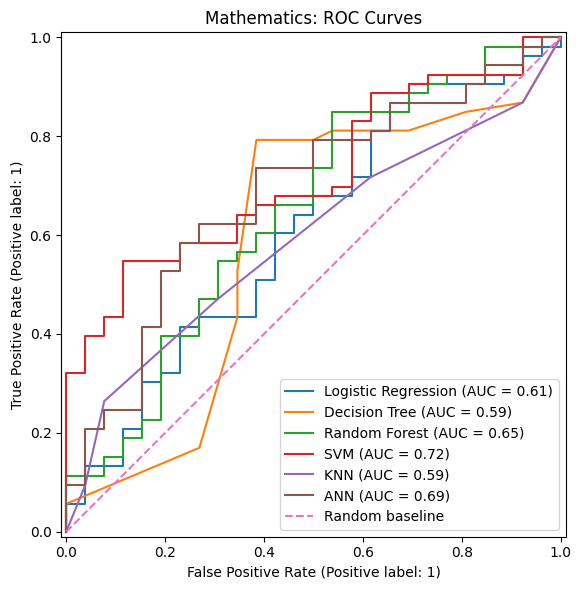

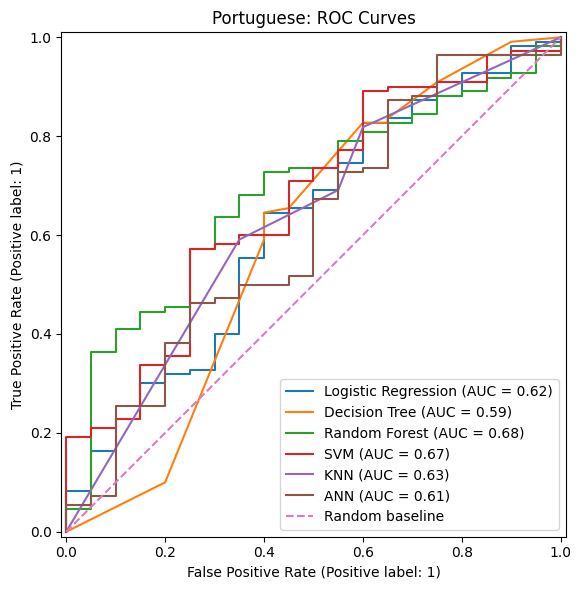


Mathematics: best model by test F1 = SVM
              precision    recall  f1-score   support

 At Risk (0)       0.62      0.38      0.48        26
    Pass (1)       0.75      0.89      0.81        53

    accuracy                           0.72        79
   macro avg       0.69      0.64      0.64        79
weighted avg       0.71      0.72      0.70        79


Portuguese: best model by test F1 = SVM
              precision    recall  f1-score   support

 At Risk (0)       0.39      0.35      0.37        20
    Pass (1)       0.88      0.90      0.89       110

    accuracy                           0.82       130
   macro avg       0.64      0.62      0.63       130
weighted avg       0.81      0.82      0.81       130


Evaluation workflow completed.
Confusion matrices: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures
ROC curves: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\figures
Metrics table: E:\PROJECTS\Mini Project

In [1]:

# ============================================================
# PHASE 14: MODEL EVALUATION
# Confusion Matrices, ROC Curves, Metrics, Saved Models
# ============================================================

from pathlib import Path
import ast
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=UserWarning)

# ------------------------------------------------------------
# 1. Locate project directories
# ------------------------------------------------------------

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        p for p in [cwd, *cwd.parents]
        if (p / "data" / "processed" / "splits").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/splits. "
        "Open the project folder and run this notebook again."
    )

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models" / "tuned"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

tuning_file = TABLES_DIR / "hyperparameter_tuning_results.csv"

if not tuning_file.exists():
    raise FileNotFoundError(
        f"Missing tuning results: {tuning_file}"
    )

tuning_df = pd.read_csv(tuning_file)

required_columns = {"Dataset", "Model", "Best_Params"}
if not required_columns.issubset(tuning_df.columns):
    raise ValueError(
        "Tuning CSV must contain Dataset, Model, and Best_Params."
    )

print("Project root:", PROJECT_ROOT)
print("Tuning records:", len(tuning_df))

# ------------------------------------------------------------
# 2. Load untouched train/test splits
# ------------------------------------------------------------

datasets = {
    "Mathematics": {
        "prefix": "mat"
    },
    "Portuguese": {
        "prefix": "por"
    }
}

for dataset_name, data in datasets.items():
    prefix = data["prefix"]

    data["X_train"] = pd.read_csv(
        SPLIT_DIR / f"{prefix}_X_train.csv"
    )
    data["X_test"] = pd.read_csv(
        SPLIT_DIR / f"{prefix}_X_test.csv"
    )
    data["y_train"] = pd.read_csv(
        SPLIT_DIR / f"{prefix}_y_train.csv"
    ).squeeze("columns")
    data["y_test"] = pd.read_csv(
        SPLIT_DIR / f"{prefix}_y_test.csv"
    ).squeeze("columns")

    assert list(data["X_train"].columns) == list(
        data["X_test"].columns
    ), f"{dataset_name}: train/test columns differ"

    assert len(data["X_train"]) == len(data["y_train"])
    assert len(data["X_test"]) == len(data["y_test"])
    assert set(data["y_train"].unique()).issubset({0, 1})
    assert set(data["y_test"].unique()).issubset({0, 1})

    print(
        f"{dataset_name}: "
        f"train={data['X_train'].shape}, "
        f"test={data['X_test'].shape}"
    )

# ------------------------------------------------------------
# 3. Define model types
# ------------------------------------------------------------

def create_estimator(model_name):
    if model_name == "Logistic Regression":
        return LogisticRegression(
            max_iter=2000,
            random_state=42
        )

    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=42)

    if model_name == "Random Forest":
        return RandomForestClassifier(
            random_state=42,
            n_jobs=1
        )

    if model_name == "SVM":
        return SVC(
            probability=True,
            random_state=42
        )

    if model_name == "KNN":
        return KNeighborsClassifier()

    if model_name == "ANN":
        return MLPClassifier(
            max_iter=500,
            early_stopping=True,
            random_state=42
        )

    raise ValueError(f"Unknown model: {model_name}")

# ------------------------------------------------------------
# 4. Refit best configurations and evaluate test data
# ------------------------------------------------------------

evaluation_rows = []
all_predictions = {}

for dataset_name, data in datasets.items():

    X_train = data["X_train"]
    X_test = data["X_test"]
    y_train = data["y_train"]
    y_test = data["y_test"]

    categorical_cols = X_train.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    numeric_cols = [
        col for col in X_train.columns
        if col not in categorical_cols
    ]

    for _, tuning_row in tuning_df[
        tuning_df["Dataset"] == dataset_name
    ].iterrows():

        model_name = tuning_row["Model"]
        best_params = ast.literal_eval(
            tuning_row["Best_Params"]
        )

        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "numeric",
                    StandardScaler(),
                    numeric_cols
                ),
                (
                    "categorical",
                    OneHotEncoder(handle_unknown="ignore"),
                    categorical_cols
                )
            ],
            remainder="drop"
        )

        estimator = create_estimator(model_name)

        model = Pipeline([
            ("preprocess", preprocessor),
            ("smote", SMOTE(
                random_state=42,
                k_neighbors=5
            )),
            ("model", estimator)
        ])

        # Apply the parameters found by GridSearchCV
        model.set_params(**best_params)

        # Fit using training data only
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_score = model.predict_proba(X_test)[:, 1]

        metrics = {
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1_Score": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y_test, y_score)
        }

        evaluation_rows.append(metrics)

        all_predictions[(dataset_name, model_name)] = {
            "y_test": y_test.to_numpy(),
            "y_pred": y_pred,
            "y_score": y_score
        }

        safe_dataset = dataset_name.lower()
        safe_model = (
            model_name.lower()
            .replace(" ", "_")
        )

        # Save fitted pipeline for later explainability/deployment
        model_path = MODELS_DIR / (
            f"{safe_dataset}_{safe_model}.joblib"
        )
        joblib.dump(model, model_path)

        # Confusion matrix
        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        )

        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["At Risk (0)", "Pass (1)"]
        ).plot(
            ax=ax,
            cmap="Blues",
            values_format="d",
            colorbar=False
        )

        ax.set_title(
            f"{dataset_name} - {model_name}\nConfusion Matrix"
        )
        fig.tight_layout()

        cm_path = FIGURES_DIR / (
            f"{safe_dataset}_{safe_model}_confusion_matrix.png"
        )
        fig.savefig(cm_path, dpi=300, bbox_inches="tight")
        plt.close(fig)

        print(
            f"Evaluated {dataset_name} - {model_name} | "
            f"F1={metrics['F1_Score']:.4f}"
        )

# ------------------------------------------------------------
# 5. Save final metrics table
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_rows)

evaluation_path = TABLES_DIR / "final_model_evaluation.csv"
evaluation_df.to_csv(evaluation_path, index=False)

print("\nFINAL TEST-SET EVALUATION")
display(
    evaluation_df.sort_values(
        ["Dataset", "F1_Score"],
        ascending=[True, False]
    ).round(4)
)

print("\nSaved evaluation table:", evaluation_path)
print("Saved fitted models:", MODELS_DIR)

# ------------------------------------------------------------
# 6. ROC curves: one figure per dataset
# ------------------------------------------------------------

for dataset_name, data in datasets.items():

    y_test = data["y_test"]

    fig, ax = plt.subplots(figsize=(8, 6))

    for model_name, _ in tuning_df[
        tuning_df["Dataset"] == dataset_name
    ][["Model", "Best_Params"]].iterrows():

        model_name = tuning_df.loc[model_name, "Model"]
        predictions = all_predictions.get(
            (dataset_name, model_name)
        )

        if predictions is None:
            continue

        RocCurveDisplay.from_predictions(
            predictions["y_test"],
            predictions["y_score"],
            name=model_name,
            ax=ax
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random baseline"
    )

    ax.set_title(f"{dataset_name}: ROC Curves")
    ax.legend(loc="lower right")
    fig.tight_layout()

    roc_path = FIGURES_DIR / (
        f"{dataset_name.lower()}_roc_curves.png"
    )
    fig.savefig(roc_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 7. Classification report for the best-F1 model per dataset
# ------------------------------------------------------------

for dataset_name in datasets:
    subset = evaluation_df[
        evaluation_df["Dataset"] == dataset_name
    ].sort_values("F1_Score", ascending=False)

    best_model_name = subset.iloc[0]["Model"]
    best_predictions = all_predictions[
        (dataset_name, best_model_name)
    ]

    print(
        f"\n{dataset_name}: best model by test F1 = "
        f"{best_model_name}"
    )
    print(
        classification_report(
            best_predictions["y_test"],
            best_predictions["y_pred"],
            labels=[0, 1],
            target_names=["At Risk (0)", "Pass (1)"],
            zero_division=0
        )
    )

print("\nEvaluation workflow completed.")
print("Confusion matrices:", FIGURES_DIR)
print("ROC curves:", FIGURES_DIR)
print("Metrics table:", evaluation_path)


In [2]:

from pathlib import Path
import pandas as pd

# Find the project root from the current notebook directory
current = Path.cwd().resolve()
PROJECT_ROOT = current

while not (PROJECT_ROOT / "README.md").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not locate project root containing README.md. "
            "Set PROJECT_ROOT manually."
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

# 1. Inspect saved evaluation results
evaluation_file = (
    PROJECT_ROOT / "results" / "tables" / "final_model_evaluation.csv"
)

if not evaluation_file.exists():
    raise FileNotFoundError(
        f"Evaluation results not found: {evaluation_file}"
    )

results = pd.read_csv(evaluation_file)

print("\nEvaluation file:", evaluation_file)
print("Rows:", len(results))
print("Columns:", results.columns.tolist())
display(results)

# 2. Identify the best model by F1-score for each dataset
required_columns = {"Dataset", "Model", "F1_Score"}

if required_columns.issubset(results.columns):
    results["F1_Score"] = pd.to_numeric(
        results["F1_Score"], errors="coerce"
    )

    best_models = (
        results.sort_values("F1_Score", ascending=False)
        .groupby("Dataset", as_index=False)
        .first()
    )

    print("\nBEST MODEL BY F1-SCORE")
    display(best_models)
else:
    print(
        "\nColumn names differ from the expected names. "
        "Check the displayed columns before comparing models."
    )

# 3. Inspect the input files used by the project
print("\nINPUT DATA FILE AUDIT")

folders = [
    PROJECT_ROOT / "data" / "processed" / "splits",
    PROJECT_ROOT / "data" / "processed" / "scaled",
    PROJECT_ROOT / "data" / "processed" / "model_ready",
]

for folder in folders:
    print(f"\nFolder: {folder}")
    if folder.exists():
        for file in sorted(folder.glob("*.csv")):
            try:
                data = pd.read_csv(file)
                print(f"{file.name}: {data.shape}")
            except Exception as exc:
                print(f"{file.name}: Could not read ({exc})")
    else:
        print("Folder does not exist.")

# 4. Locate generated evaluation figures
print("\nEVALUATION FIGURES")

figures_dir = PROJECT_ROOT / "results" / "figures"

if figures_dir.exists():
    figure_files = sorted(
        file for file in figures_dir.rglob("*")
        if file.is_file()
    )
    for file in figure_files:
        print(file.relative_to(PROJECT_ROOT))
else:
    print("No results/figures directory found.")

print("\nAudit completed. Review the feature counts before finalizing results.")


Project root: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction

Evaluation file: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\final_model_evaluation.csv
Rows: 12
Columns: ['Dataset', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']


,Dataset,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Mathematics,Logistic Regression,0.594937,0.723404,0.641509,0.680000,0.605951
1,Mathematics,Decision Tree,0.734177,0.807692,0.792453,0.800000,0.592888
2,Mathematics,Random Forest,0.670886,0.714286,0.849057,0.775862,0.646589
3,Mathematics,SVM,0.721519,0.746032,0.886792,0.810345,0.719884
4,Mathematics,KNN,0.544304,0.757576,0.471698,0.581395,0.592163
5,Mathematics,ANN,0.696203,0.763636,0.792453,0.777778,0.685776
6,Portuguese,Logistic Regression,0.684615,0.879121,0.727273,0.796020,0.617727
7,Portuguese,Decision Tree,0.753846,0.875000,0.827273,0.850467,0.593409
8,Portuguese,Random Forest,0.784615,0.853448,0.900000,0.876106,0.684091
9,Portuguese,SVM,0.815385,0.883929,0.900000,0.891892,0.665455



BEST MODEL BY F1-SCORE


,Dataset,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Mathematics,SVM,0.721519,0.746032,0.886792,0.810345,0.719884
1,Portuguese,SVM,0.815385,0.883929,0.900000,0.891892,0.665455



INPUT DATA FILE AUDIT

Folder: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\splits
mat_X_test.csv: (79, 30)
mat_X_train.csv: (316, 30)
mat_y_test.csv: (79, 1)
mat_y_train.csv: (316, 1)
por_X_test.csv: (130, 30)
por_X_train.csv: (519, 30)
por_y_test.csv: (130, 1)
por_y_train.csv: (519, 1)

Folder: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\scaled
mat_X_test_scaled.csv: (79, 30)
mat_X_train_scaled.csv: (316, 30)
por_X_test_scaled.csv: (130, 30)
por_X_train_scaled.csv: (519, 30)

Folder: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\model_ready
mat_X_test_processed.csv: (79, 56)
mat_X_train_balanced.csv: (424, 56)
mat_y_test.csv: (79, 1)
mat_y_train_balanced.csv: (424, 1)
por_X_test_processed.csv: (130, 56)
por_X_train_balanced.csv: (878, 56)
por_y_test.csv: (130, 1)
por_y_train_balanced.csv: (878, 1)
student_mat_features.csv: (395, 31)
student_mat_test.csv: (79, 59)
student_mat_train.c

In [3]:

from pathlib import Path
import pandas as pd

# Locate project root
PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "README.md").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project root not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

processed_dir = PROJECT_ROOT / "data" / "processed"
model_ready_dir = processed_dir / "model_ready"
scaled_dir = processed_dir / "scaled"
splits_dir = processed_dir / "splits"

print("PROJECT ROOT:", PROJECT_ROOT)

# Inspect the actual columns in each feature file
files_to_check = [
    splits_dir / "mat_X_train.csv",
    scaled_dir / "mat_X_train_scaled.csv",
    model_ready_dir / "mat_X_train_balanced.csv",
    model_ready_dir / "mat_X_test_processed.csv",
    model_ready_dir / "por_X_train_balanced.csv",
    model_ready_dir / "por_X_test_processed.csv",
]

for file_path in files_to_check:
    print("\n" + "=" * 65)
    print("FILE:", file_path.relative_to(PROJECT_ROOT))

    if not file_path.exists():
        print("MISSING")
        continue

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("First 10 columns:", df.columns[:10].tolist())
    print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())
    print("Missing values:", int(df.isna().sum().sum()))

# Check that the saved evaluation results exist
evaluation_file = (
    PROJECT_ROOT / "results" / "tables" / "final_model_evaluation.csv"
)

if evaluation_file.exists():
    evaluation = pd.read_csv(evaluation_file)
    print("\n" + "=" * 65)
    print("EVALUATION RESULTS")
    print("Shape:", evaluation.shape)
    print(evaluation.to_string(index=False))
else:
    print("\nEvaluation CSV is missing:", evaluation_file)


PROJECT ROOT: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction

FILE: data\processed\splits\mat_X_train.csv
Shape: (316, 30)
First 10 columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob']
Duplicate column names: []
Missing values: 0

FILE: data\processed\scaled\mat_X_train_scaled.csv
Shape: (316, 30)
First 10 columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob']
Duplicate column names: []
Missing values: 0

FILE: data\processed\model_ready\mat_X_train_balanced.csv
Shape: (424, 56)
First 10 columns: ['categorical__school_GP', 'categorical__school_MS', 'categorical__sex_F', 'categorical__sex_M', 'categorical__address_R', 'categorical__address_U', 'categorical__famsize_GT3', 'categorical__famsize_LE3', 'categorical__Pstatus_A', 'categorical__Pstatus_T']
Duplicate column names: []
Missing values: 0

FILE: data\processed\model_ready\mat_X_test_processed.csv
Shape: (79, 56)
First 10 colum

In [4]:

from pathlib import Path
import pandas as pd
import numpy as np

# Locate the project root from this notebook's working directory.
# If PROJECT_ROOT already exists in an earlier cell, reuse it.
try:
    PROJECT_ROOT = Path(PROJECT_ROOT).resolve()
except NameError:
    PROJECT_ROOT = Path.cwd().resolve()
    while (
        not (PROJECT_ROOT / "results").exists()
        and PROJECT_ROOT.parent != PROJECT_ROOT
    ):
        PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

EVALUATION_FILE = TABLES_DIR / "final_model_evaluation.csv"

if not EVALUATION_FILE.exists():
    raise FileNotFoundError(
        f"Evaluation results not found: {EVALUATION_FILE}\n"
        "Run the model evaluation cells first."
    )

# Load the final evaluation results
results = pd.read_csv(EVALUATION_FILE)

required_columns = {
    "Dataset", "Model", "Accuracy", "Precision",
    "Recall", "F1_Score", "ROC_AUC"
}

missing_columns = required_columns - set(results.columns)
if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

# Validate metric values
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"
]

for column in metric_columns:
    results[column] = pd.to_numeric(
        results[column], errors="coerce"
    )

if results[metric_columns].isna().any().any():
    raise ValueError(
        "Some evaluation metrics are missing or non-numeric."
    )

if not results[metric_columns].apply(
    lambda column: column.between(0, 1).all()
).all():
    raise ValueError("Metrics must be between 0 and 1.")

# Rank models separately for each dataset by F1-score
ranked_results = results.sort_values(
    ["Dataset", "F1_Score", "ROC_AUC"],
    ascending=[True, False, False]
).copy()

ranked_results["F1_Rank"] = (
    ranked_results.groupby("Dataset")["F1_Score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

comparison_file = TABLES_DIR / "model_comparison_ranked.csv"
ranked_results.to_csv(comparison_file, index=False)

# Print the best model for each dataset
print("=" * 70)
print("MODEL COMPARISON — RANKED BY TEST F1-SCORE")
print("=" * 70)

display_columns = [
    "Dataset", "Model", "Accuracy", "Precision",
    "Recall", "F1_Score", "ROC_AUC", "F1_Rank"
]

print(ranked_results[display_columns].round(4).to_string(index=False))

print("\n" + "=" * 70)
print("BEST MODEL PER DATASET")
print("=" * 70)

best_rows = ranked_results.groupby("Dataset", sort=False).head(1)

for _, row in best_rows.iterrows():
    print(f"\nDataset: {row['Dataset']}")
    print(f"Best model by F1-score: {row['Model']}")
    print(f"Accuracy: {row['Accuracy']:.4f}")
    print(f"Precision: {row['Precision']:.4f}")
    print(f"Recall: {row['Recall']:.4f}")
    print(f"F1-score: {row['F1_Score']:.4f}")
    print(f"ROC-AUC: {row['ROC_AUC']:.4f}")

# Save a concise summary for later paper writing
summary_file = TABLES_DIR / "best_model_summary.txt"

with open(summary_file, "w", encoding="utf-8") as file:
    file.write("Best model per dataset, ranked by test F1-score\n\n")

    for _, row in best_rows.iterrows():
        file.write(
            f"Dataset: {row['Dataset']}\n"
            f"Model: {row['Model']}\n"
            f"Accuracy: {row['Accuracy']:.4f}\n"
            f"Precision: {row['Precision']:.4f}\n"
            f"Recall: {row['Recall']:.4f}\n"
            f"F1-score: {row['F1_Score']:.4f}\n"
            f"ROC-AUC: {row['ROC_AUC']:.4f}\n\n"
        )

print("\nSaved comparison table:", comparison_file)
print("Saved summary:", summary_file)
print("\nComparison audit completed.")


MODEL COMPARISON — RANKED BY TEST F1-SCORE
    Dataset               Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC  F1_Rank
Mathematics                 SVM    0.7215     0.7460  0.8868    0.8103   0.7199        1
Mathematics       Decision Tree    0.7342     0.8077  0.7925    0.8000   0.5929        2
Mathematics                 ANN    0.6962     0.7636  0.7925    0.7778   0.6858        3
Mathematics       Random Forest    0.6709     0.7143  0.8491    0.7759   0.6466        4
Mathematics Logistic Regression    0.5949     0.7234  0.6415    0.6800   0.6060        5
Mathematics                 KNN    0.5443     0.7576  0.4717    0.5814   0.5922        6
 Portuguese                 SVM    0.8154     0.8839  0.9000    0.8919   0.6655        1
 Portuguese       Random Forest    0.7846     0.8534  0.9000    0.8761   0.6841        2
 Portuguese       Decision Tree    0.7538     0.8750  0.8273    0.8505   0.5934        3
 Portuguese                 ANN    0.7308     0.8713  0.8000    0.8

In [1]:

from pathlib import Path
import joblib
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Project root: notebook is inside the notebooks/ directory
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models" / "tuned"
SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits"
OUTPUT_DIR = PROJECT_ROOT / "results" / "tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = []

datasets = {
    "Mathematics": {
        "prefix": "mat",
        "model_prefix": "mathematics"
    },
    "Portuguese": {
        "prefix": "por",
        "model_prefix": "portuguese"
    }
}

model_names = [
    "logistic_regression",
    "decision_tree",
    "random_forest",
    "svm",
    "knn",
    "ann"
]

for dataset_name, config in datasets.items():
    prefix = config["prefix"]
    model_prefix = config["model_prefix"]

    # Load the original held-out test data
    X_test = pd.read_csv(SPLIT_DIR / f"{prefix}_X_test.csv")
    y_test = pd.read_csv(SPLIT_DIR / f"{prefix}_y_test.csv").squeeze()

    # Ensure labels are numeric integers: 0 = At Risk, 1 = Pass
    y_test = y_test.astype(int)

    print(f"\n{'=' * 60}")
    print(f"{dataset_name} | Test samples: {len(y_test)}")
    print("Test label counts:")
    print(y_test.map({0: "At Risk", 1: "Pass"}).value_counts())
    print("=" * 60)

    for model_name in model_names:
        model_path = MODEL_DIR / f"{model_prefix}_{model_name}.joblib"

        if not model_path.exists():
            print(f"SKIPPED: Model not found: {model_path}")
            continue

        model = joblib.load(model_path)
        y_pred = model.predict(X_test)

        # Find probability or decision scores for ROC-AUC
        y_score = None

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_test)
            classes = list(model.classes_)
            if 0 in classes:
                # Score class 0 (At Risk), our target of interest
                y_score = probabilities[:, classes.index(0)]

        elif hasattr(model, "decision_function"):
            decision_scores = model.decision_function(X_test)
            classes = list(model.classes_)

            # sklearn binary decision scores normally favor classes_[1]
            if len(classes) == 2 and classes[1] == 0:
                y_score = -decision_scores
            elif len(classes) == 2:
                y_score = decision_scores

        # Metrics for the At Risk class (label 0)
        row = {
            "Dataset": dataset_name,
            "Model": model_name.replace("_", " ").title(),
            "Accuracy": accuracy_score(y_test, y_pred),
            "At_Risk_Precision": precision_score(
                y_test, y_pred, pos_label=0, zero_division=0
            ),
            "At_Risk_Recall": recall_score(
                y_test, y_pred, pos_label=0, zero_division=0
            ),
            "At_Risk_F1": f1_score(
                y_test, y_pred, pos_label=0, zero_division=0
            ),
            "Pass_Precision": precision_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "Pass_Recall": recall_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "Pass_F1": f1_score(
                y_test, y_pred, pos_label=1, zero_division=0
            ),
            "ROC_AUC_At_Risk": (
                roc_auc_score((y_test == 0).astype(int), y_score)
                if y_score is not None
                else float("nan")
            )
        }

        results.append(row)

        print(f"\n{row['Model']}")
        print(classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["At Risk", "Pass"],
            zero_division=0
        ))

# Save a separate report so the existing results remain unchanged
if results:
    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by=["Dataset", "At_Risk_F1"],
        ascending=[True, False]
    )

    output_path = OUTPUT_DIR / "at_risk_model_evaluation.csv"
    results_df.to_csv(output_path, index=False)

    print("\nSaved evaluation results to:")
    print(output_path)

    display(results_df.round(4))
else:
    print(
        "No models were evaluated. Check MODEL_DIR, SPLIT_DIR, "
        "and the model filenames."
    )



Mathematics | Test samples: 79
Test label counts:
performance
Pass       53
At Risk    26
Name: count, dtype: int64

Logistic Regression
              precision    recall  f1-score   support

     At Risk       0.41      0.50      0.45        26
        Pass       0.72      0.64      0.68        53

    accuracy                           0.59        79
   macro avg       0.56      0.57      0.56        79
weighted avg       0.62      0.59      0.60        79


Decision Tree
              precision    recall  f1-score   support

     At Risk       0.59      0.62      0.60        26
        Pass       0.81      0.79      0.80        53

    accuracy                           0.73        79
   macro avg       0.70      0.70      0.70        79
weighted avg       0.74      0.73      0.74        79


Random Forest
              precision    recall  f1-score   support

     At Risk       0.50      0.31      0.38        26
        Pass       0.71      0.85      0.78        53

    accuracy  

,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,Pass_Precision,Pass_Recall,Pass_F1,ROC_AUC_At_Risk
1,Mathematics,Decision Tree,0.7342,0.5926,0.6154,0.6038,0.8077,0.7925,0.8000,0.5929
5,Mathematics,Ann,0.6962,0.5417,0.5000,0.5200,0.7636,0.7925,0.7778,0.6858
4,Mathematics,Knn,0.5443,0.3913,0.6923,0.5000,0.7576,0.4717,0.5814,0.5922
3,Mathematics,Svm,0.7215,0.6250,0.3846,0.4762,0.7460,0.8868,0.8103,0.7199
0,Mathematics,Logistic Regression,0.5949,0.4062,0.5000,0.4483,0.7234,0.6415,0.6800,0.6060
2,Mathematics,Random Forest,0.6709,0.5000,0.3077,0.3810,0.7143,0.8491,0.7759,0.6466
9,Portuguese,Svm,0.8154,0.3889,0.3500,0.3684,0.8839,0.9000,0.8919,0.6655
6,Portuguese,Logistic Regression,0.6846,0.2308,0.4500,0.3051,0.8791,0.7273,0.7960,0.6177
7,Portuguese,Decision Tree,0.7538,0.2692,0.3500,0.3043,0.8750,0.8273,0.8505,0.5934
10,Portuguese,Knn,0.6538,0.2093,0.4500,0.2857,0.8736,0.6909,0.7716,0.6330


In [2]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

results_path = (
    project_root
    / "results"
    / "tables"
    / "at_risk_model_evaluation.csv"
)

df = pd.read_csv(results_path)

# Rank models separately for each dataset by At Risk F1,
# then At Risk recall as a tie-breaker.
df = df.sort_values(
    ["Dataset", "At_Risk_F1", "At_Risk_Recall"],
    ascending=[True, False, False]
)

columns_to_show = [
    "Dataset",
    "Model",
    "Accuracy",
    "At_Risk_Precision",
    "At_Risk_Recall",
    "At_Risk_F1",
    "Pass_F1",
    "ROC_AUC_At_Risk"
]

print("MODEL RANKING FOR AT RISK DETECTION")
display(df[columns_to_show].round(3))

print("\nTOP MODEL FOR EACH DATASET")
top_models = df.groupby("Dataset", sort=False).head(1)
display(top_models[columns_to_show].round(3))

# Save the ranked results
ranked_path = (
    project_root
    / "results"
    / "tables"
    / "at_risk_model_ranking.csv"
)
df.to_csv(ranked_path, index=False)

print(f"\nRanked results saved to: {ranked_path}")


MODEL RANKING FOR AT RISK DETECTION


,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,Pass_F1,ROC_AUC_At_Risk
0,Mathematics,Decision Tree,0.734,0.593,0.615,0.604,0.800,0.593
1,Mathematics,Ann,0.696,0.542,0.500,0.520,0.778,0.686
2,Mathematics,Knn,0.544,0.391,0.692,0.500,0.581,0.592
3,Mathematics,Svm,0.722,0.625,0.385,0.476,0.810,0.720
4,Mathematics,Logistic Regression,0.595,0.406,0.500,0.448,0.680,0.606
5,Mathematics,Random Forest,0.671,0.500,0.308,0.381,0.776,0.647
6,Portuguese,Svm,0.815,0.389,0.350,0.368,0.892,0.665
7,Portuguese,Logistic Regression,0.685,0.231,0.450,0.305,0.796,0.618
8,Portuguese,Decision Tree,0.754,0.269,0.350,0.304,0.850,0.593
9,Portuguese,Knn,0.654,0.209,0.450,0.286,0.772,0.633



TOP MODEL FOR EACH DATASET


,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,Pass_F1,ROC_AUC_At_Risk
0,Mathematics,Decision Tree,0.734,0.593,0.615,0.604,0.800,0.593
6,Portuguese,Svm,0.815,0.389,0.350,0.368,0.892,0.665



Ranked results saved to: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\at_risk_model_ranking.csv


In [3]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

path = (
    project_root
    / "results"
    / "tables"
    / "at_risk_model_ranking.csv"
)

df = pd.read_csv(path)

for dataset in ["Mathematics", "Portuguese"]:
    subset = df[df["Dataset"] == dataset].sort_values(
        ["At_Risk_F1", "At_Risk_Recall"],
        ascending=False
    )

    print(f"\n{'=' * 65}")
    print(f"{dataset.upper()} — AT RISK MODEL RANKING")
    print("=" * 65)

    display(
        subset[
            [
                "Model",
                "Accuracy",
                "At_Risk_Precision",
                "At_Risk_Recall",
                "At_Risk_F1",
                "ROC_AUC_At_Risk"
            ]
        ].round(3).reset_index(drop=True)
    )



MATHEMATICS — AT RISK MODEL RANKING


,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,ROC_AUC_At_Risk
0,Decision Tree,0.734,0.593,0.615,0.604,0.593
1,Ann,0.696,0.542,0.500,0.520,0.686
2,Knn,0.544,0.391,0.692,0.500,0.592
3,Svm,0.722,0.625,0.385,0.476,0.720
4,Logistic Regression,0.595,0.406,0.500,0.448,0.606
5,Random Forest,0.671,0.500,0.308,0.381,0.647



PORTUGUESE — AT RISK MODEL RANKING


,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,ROC_AUC_At_Risk
0,Svm,0.815,0.389,0.35,0.368,0.665
1,Logistic Regression,0.685,0.231,0.45,0.305,0.618
2,Decision Tree,0.754,0.269,0.35,0.304,0.593
3,Knn,0.654,0.209,0.45,0.286,0.633
4,Ann,0.731,0.241,0.35,0.286,0.609
5,Random Forest,0.785,0.214,0.15,0.176,0.684


Project root: E:\PROJECTS\Mini Project\Project\Student-Performance-Prediction
Confusion-matrix images found: 12

results\figures\mathematics_random_forest_confusion_matrix.png


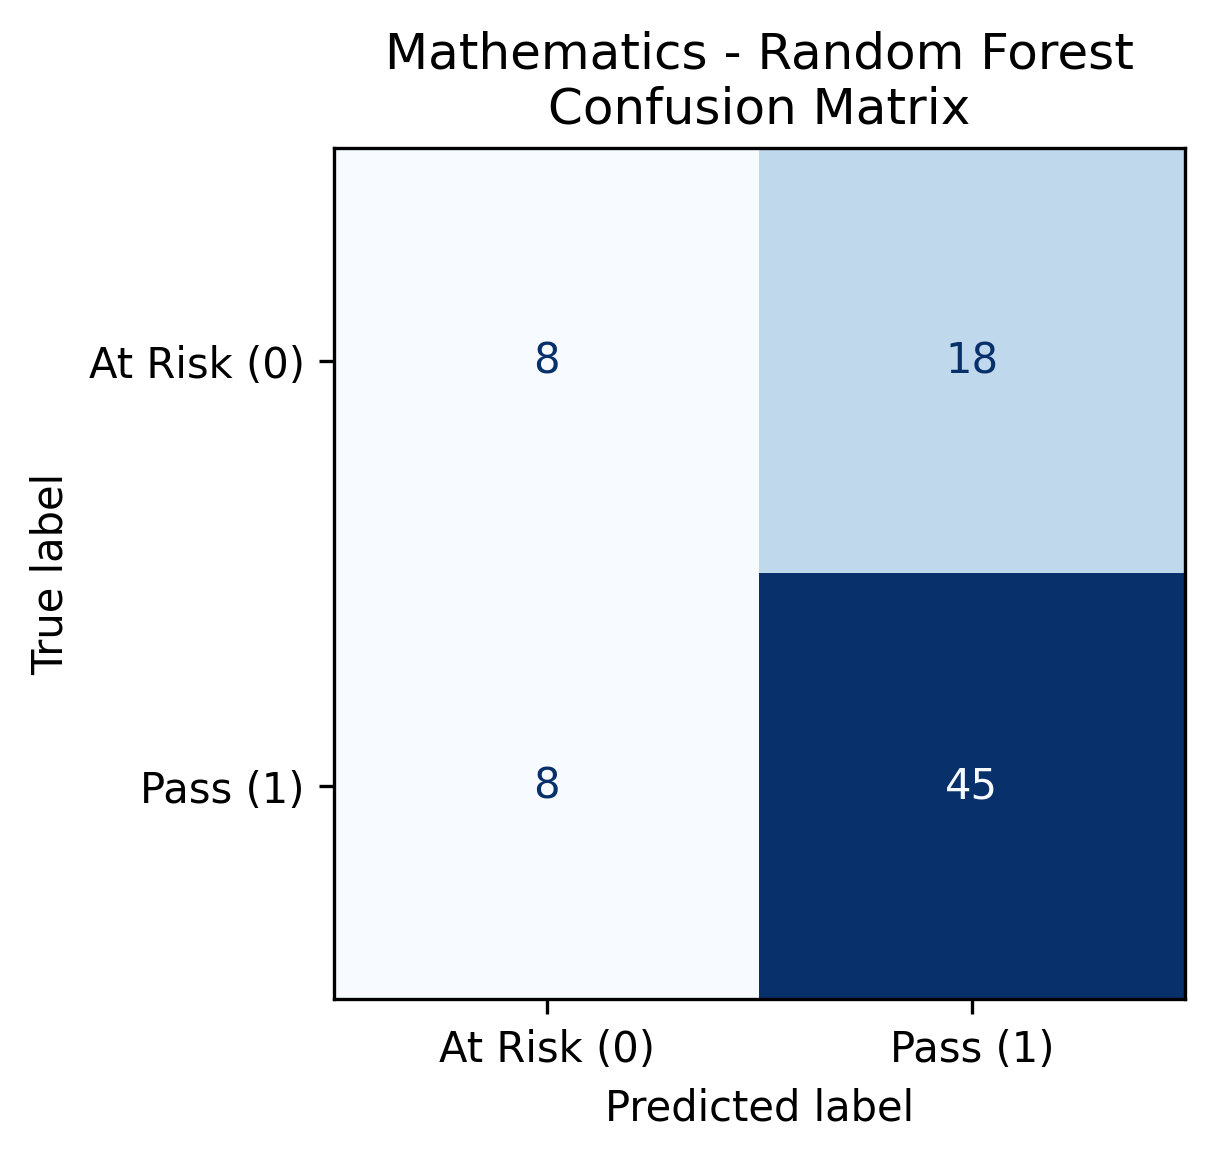


results\figures\portuguese_random_forest_confusion_matrix.png


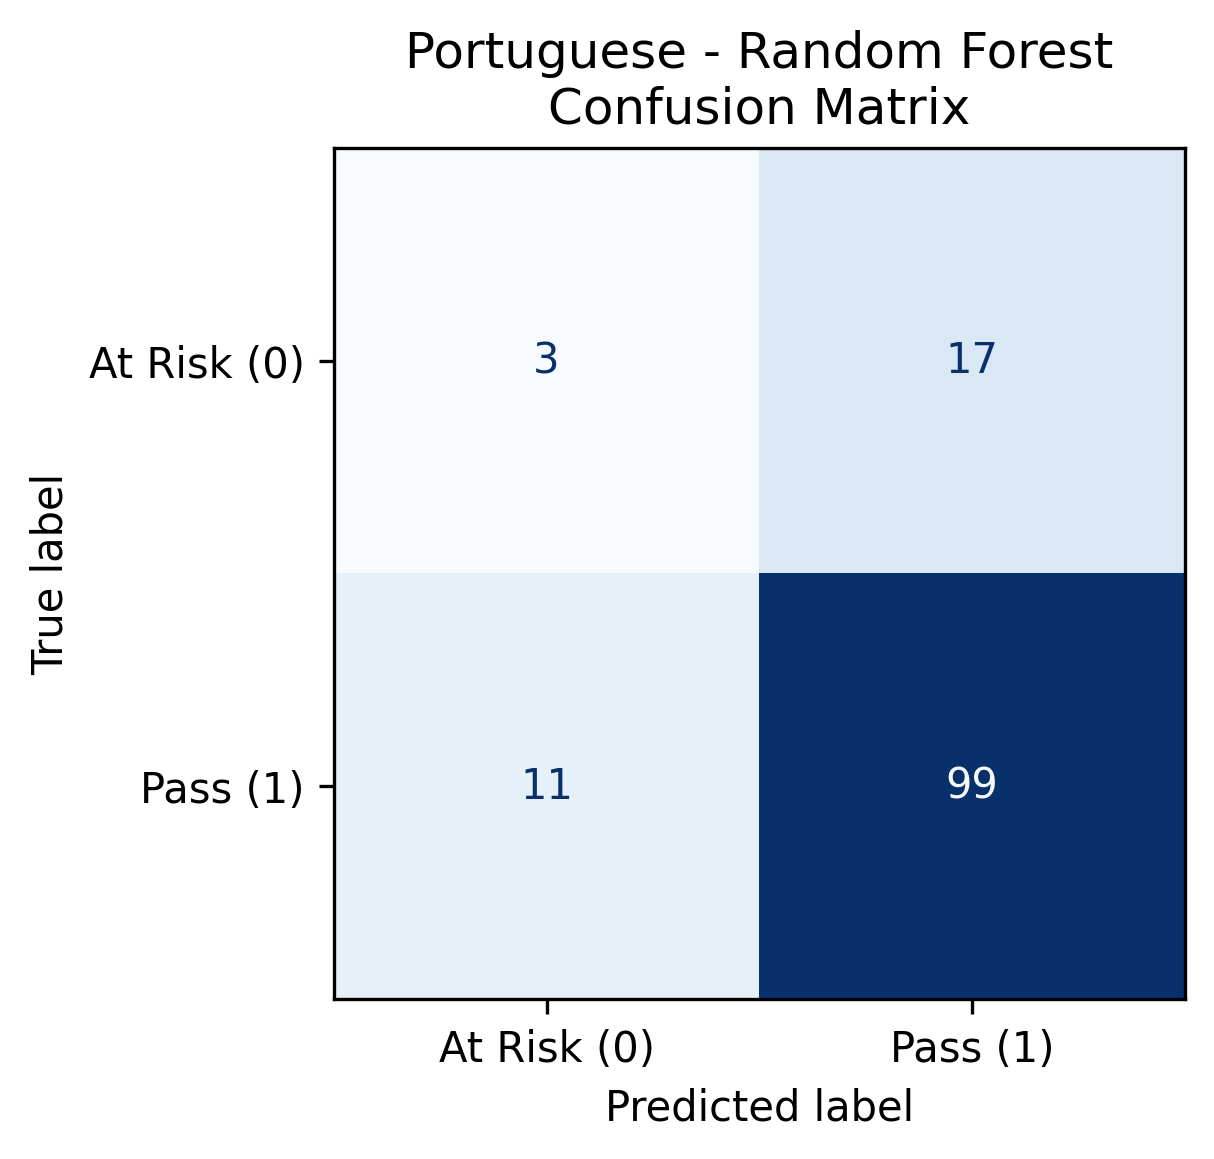

In [1]:
from pathlib import Path
from IPython.display import display, Image

# Find the project root
project_root = Path.cwd().resolve()

while not (
    (project_root / "results").is_dir()
    and (project_root / "notebooks").is_dir()
):
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent

# Locate existing confusion-matrix images
image_files = [
    path
    for path in (project_root / "results").rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".png", ".jpg", ".jpeg"}
    and "confusion" in path.name.lower()
]

print(f"Project root: {project_root}")
print(f"Confusion-matrix images found: {len(image_files)}")

# Show Random Forest confusion matrices first
rf_images = [
    path for path in image_files
    if "random_forest" in path.name.lower()
    or "random forest" in path.name.lower()
    or "randomforest" in path.name.lower()
]

if rf_images:
    for path in sorted(rf_images):
        print(f"\n{path.relative_to(project_root)}")
        display(Image(filename=str(path)))
else:
    print("\nRandom Forest images were not identified by filename.")
    for path in sorted(image_files):
        print(path.relative_to(project_root))

In [2]:
from pathlib import Path
import pandas as pd

root = Path.cwd().resolve()

while not (root / "results" / "tables").is_dir():
    if root.parent == root:
        raise FileNotFoundError("Project root not found.")
    root = root.parent

path = root / "results" / "tables" / "at_risk_tuned_model_test_results.csv"
df = pd.read_csv(path)

display(
    df[df["Model"].str.contains("Random Forest", case=False)][
        [
            "Dataset",
            "Model",
            "Accuracy",
            "At_Risk_Precision",
            "At_Risk_Recall",
            "At_Risk_F1",
            "Pass_F1",
        ]
    ].round(4)
)

,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,Pass_F1
2,Mathematics,Random Forest,0.6835,0.5385,0.2692,0.3590,0.7899
8,Portuguese,Random Forest,0.7692,0.1875,0.1500,0.1667,0.8661


In [3]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

root = Path.cwd().resolve()

while not (
    (root / "models" / "tuned_at_risk").is_dir()
    and (root / "data" / "processed" / "splits").is_dir()
):
    if root.parent == root:
        raise FileNotFoundError("Project root not found.")
    root = root.parent

for dataset in ["mathematics", "portuguese"]:
    model_path = (
        root / "models" / "tuned_at_risk"
        / f"{dataset}_random_forest.joblib"
    )

    split_dir = root / "data" / "processed" / "splits"
    X_test = pd.read_csv(split_dir / f"{'mat' if dataset == 'mathematics' else 'por'}_X_test.csv")
    y_test = pd.read_csv(split_dir / f"{'mat' if dataset == 'mathematics' else 'por'}_y_test.csv").squeeze()

    import joblib
    model = joblib.load(model_path)
    y_pred = model.predict(X_test)

    print(f"\n{dataset.title()} — Random Forest")
    print("Confusion matrix (labels [0, 1]):")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("At Risk precision:", round(
        precision_score(y_test, y_pred, pos_label=0, zero_division=0), 4
    ))
    print("At Risk recall:", round(
        recall_score(y_test, y_pred, pos_label=0, zero_division=0), 4
    ))
    print("At Risk F1:", round(
        f1_score(y_test, y_pred, pos_label=0, zero_division=0), 4
    ))
    print("Pass F1:", round(
        f1_score(y_test, y_pred, pos_label=1, zero_division=0), 4
    ))


Mathematics — Random Forest
Confusion matrix (labels [0, 1]):
[[ 7 19]
 [ 6 47]]
Accuracy: 0.6835
At Risk precision: 0.5385
At Risk recall: 0.2692
At Risk F1: 0.359
Pass F1: 0.7899

Portuguese — Random Forest
Confusion matrix (labels [0, 1]):
[[ 3 17]
 [13 97]]
Accuracy: 0.7692
At Risk precision: 0.1875
At Risk recall: 0.15
At Risk F1: 0.1667
Pass F1: 0.8661


In [4]:
from pathlib import Path
import pandas as pd

root = Path.cwd().resolve()

while not (root / "results" / "tables").is_dir():
    if root.parent == root:
        raise FileNotFoundError("Project root not found.")
    root = root.parent

results_path = (
    root / "results" / "tables"
    / "at_risk_tuned_model_test_results.csv"
)

df = pd.read_csv(results_path)

columns = [
    "Dataset",
    "Model",
    "Accuracy",
    "At_Risk_Precision",
    "At_Risk_Recall",
    "At_Risk_F1",
    "At_Risk_ROC_AUC",
    "Pass_F1",
]

comparison = (
    df[columns]
    .sort_values(
        ["Dataset", "At_Risk_F1"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

display(comparison.round(4))

print("\nBest model by At Risk F1 for each dataset:")
display(
    comparison.loc[
        comparison.groupby("Dataset")["At_Risk_F1"].idxmax()
    ].round(4).reset_index(drop=True)
)

,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,At_Risk_ROC_AUC,Pass_F1
0,Mathematics,Decision Tree,0.7342,0.5926,0.6154,0.6038,0.5929,0.8000
1,Mathematics,KNN,0.5823,0.4222,0.7308,0.5352,0.6306,0.6207
2,Mathematics,ANN,0.6582,0.4800,0.4615,0.4706,0.6538,0.7477
3,Mathematics,SVM,0.5696,0.3889,0.5385,0.4516,0.6161,0.6458
4,Mathematics,Logistic Regression,0.5949,0.4062,0.5000,0.4483,0.6060,0.6800
5,Mathematics,Random Forest,0.6835,0.5385,0.2692,0.3590,0.6538,0.7899
6,Portuguese,SVM,0.7077,0.2750,0.5500,0.3667,0.6427,0.8100
7,Portuguese,Logistic Regression,0.6846,0.2308,0.4500,0.3051,0.6177,0.7960
8,Portuguese,Decision Tree,0.7538,0.2692,0.3500,0.3043,0.5934,0.8505
9,Portuguese,KNN,0.6538,0.2093,0.4500,0.2857,0.6330,0.7716



Best model by At Risk F1 for each dataset:


,Dataset,Model,Accuracy,At_Risk_Precision,At_Risk_Recall,At_Risk_F1,At_Risk_ROC_AUC,Pass_F1
0,Mathematics,Decision Tree,0.7342,0.5926,0.6154,0.6038,0.5929,0.80
1,Portuguese,SVM,0.7077,0.2750,0.5500,0.3667,0.6427,0.81
